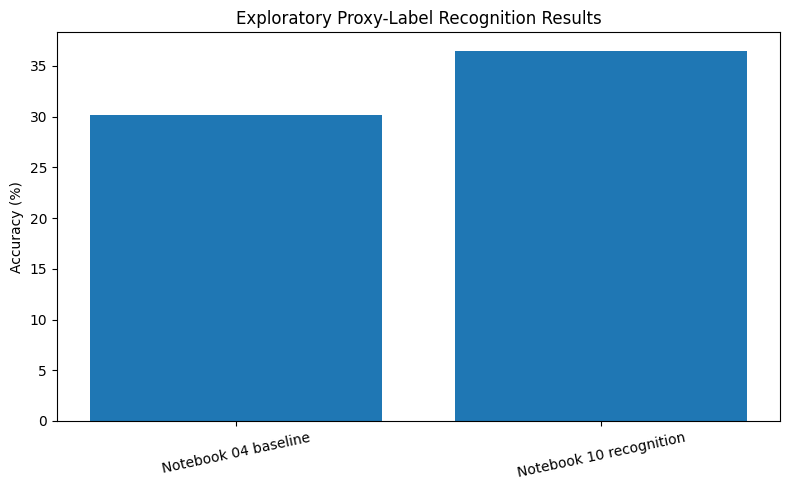

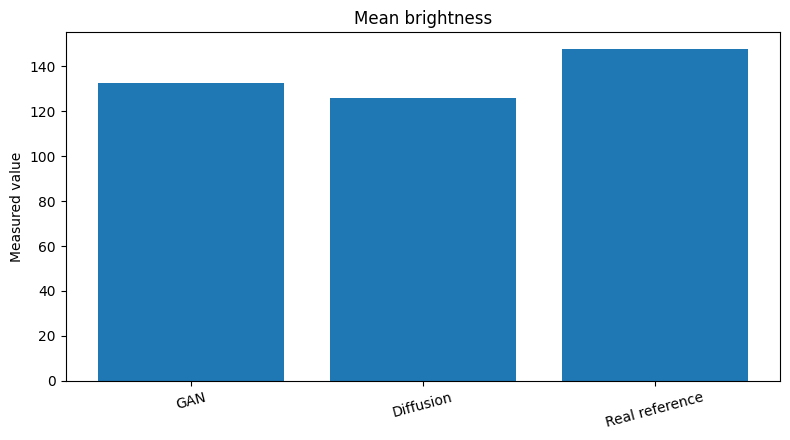

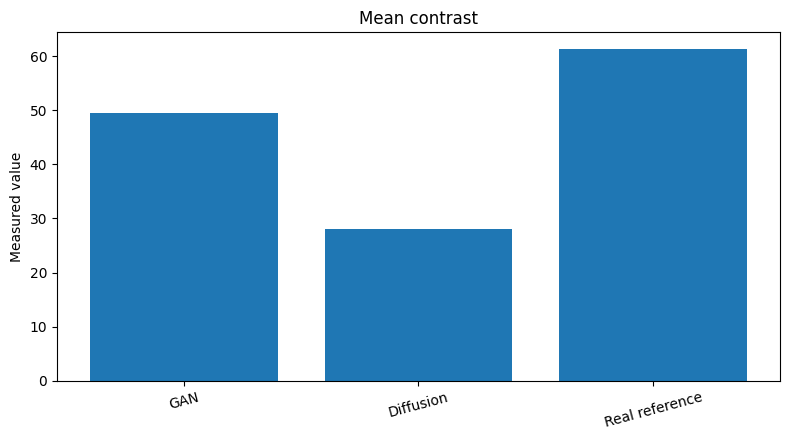

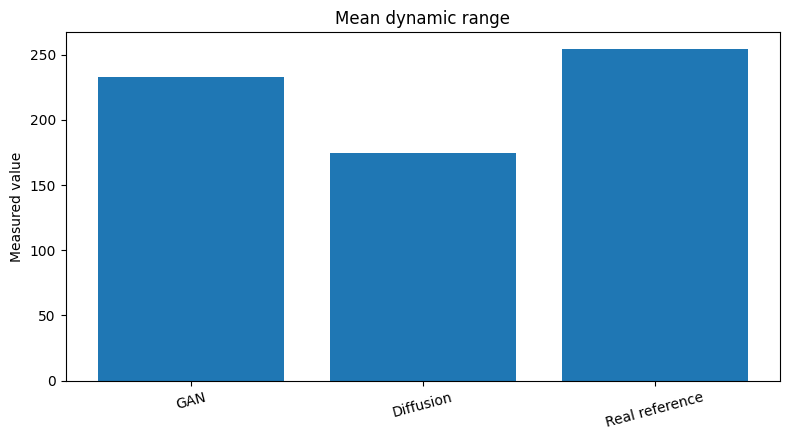

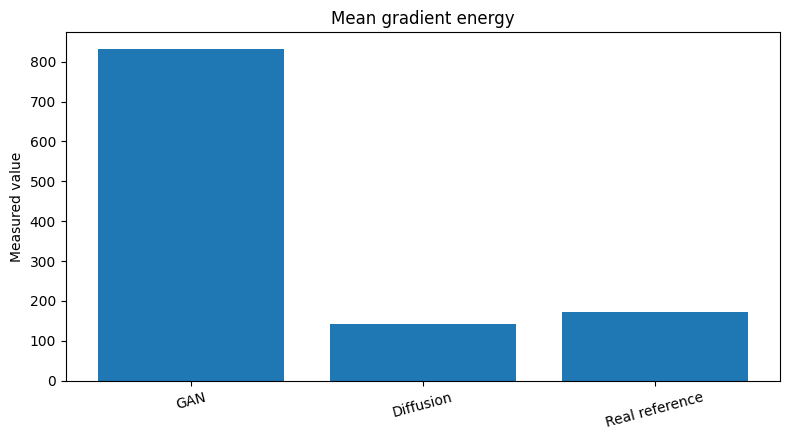

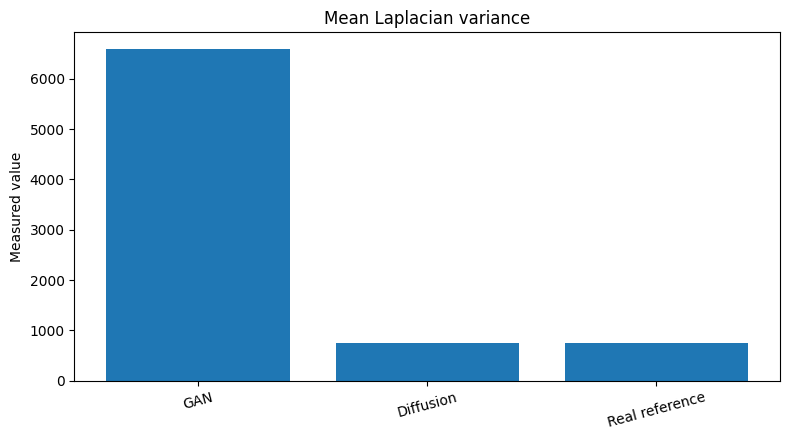

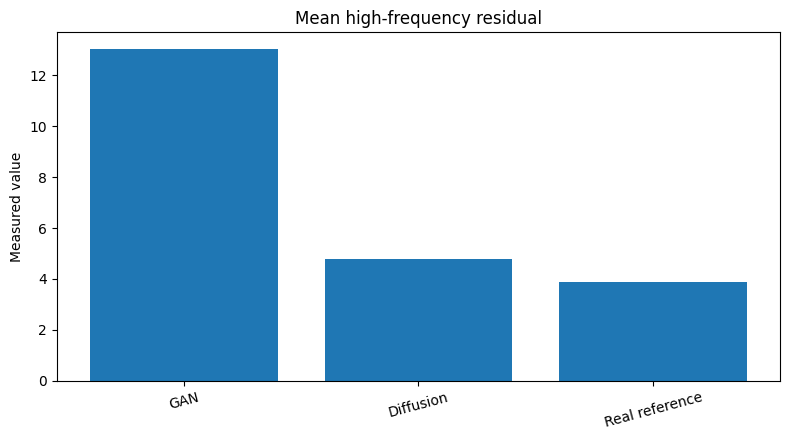

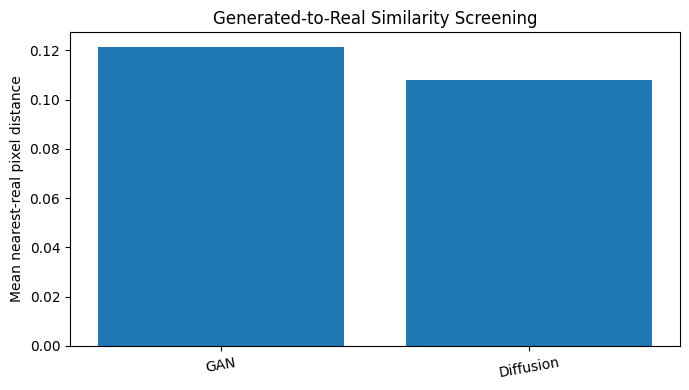


NOTEBOOK 14 COMPLETED
Output folder: /kaggle/working/nd_iris_project/notebook14_visualization_ablation
ZIP: /kaggle/working/nd_iris_project/ND_Iris_Notebook14_Results.zip
ZIP files: 15
ZIP integrity: PASSED
Conclusion file: /kaggle/working/nd_iris_project/notebook14_visualization_ablation/Notebook14_Conclusion.md
Runtime seconds: 2.07

ARTIFACT INVENTORY


,notebook_folder,file_count,total_size_mb
0,notebook01_dataset_analysis,6,0.432
1,notebook02_preprocessing,6238,159.649
2,notebook03_quality_assessment,13,1.991
3,notebook04_baseline_recognition,10,44.695
4,notebook05_diffusion_training,0,0.000
5,notebook05_traditional_augmentation,12472,293.917
6,notebook06_gan_augmentation,44,9.219
7,notebook07_diffusion_training,22,4.997
8,notebook08_quality_diversity,13,0.362
9,notebook09_dataset_augmentation,18745,455.663



RECOGNITION RESULTS SUMMARY


,experiment,test_accuracy_percent,label_type,trained_with_generated_augmentation,interpretation
0,Notebook 04 baseline,30.1800,Filename-derived proxy labels,False,Exploratory proxy-label result; not verified i...
1,Notebook 10 recognition,36.4905,Filename-derived proxy labels,False,Real images only; not an augmentation-benefit ...



ABLATION COMPARABILITY TABLE


,comparison,result,validity,reason
0,Baseline vs Notebook 10 recognition,30.18% vs 36.4905% test accuracy,Not a controlled ablation,Proxy-label setup and splits differ; Notebook ...
1,GAN vs diffusion image statistics,"Different brightness, contrast, edge and high-...",Exploratory descriptive comparison,Small unequal sample counts and low-level metr...
2,Membership-inference simulation,Accuracy 49.8667%; ROC-AUC 0.49994,Simulation only,Random membership assignment; not an attack on...
3,Generated-to-real similarity,No exact normalized matches in 55 generated sa...,Exploratory screening,"Only 1,500 real reference images were sampled;..."


In [19]:

# ============================================================
# NOTEBOOK 14: RESULT VISUALIZATION AND ABLATION STUDIES
# Dataset: NDCLD15 / ND-Iris
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, time, zipfile, shutil

# -------------------- CONFIGURATION --------------------------
PROJECT = Path("/kaggle/working/nd_iris_project")
OUT = PROJECT / "notebook14_visualization_ablation"
OUT.mkdir(parents=True, exist_ok=True)

start_time = time.time()

# -------------------- LOAD EXISTING RESULTS -------------------
def read_csv_if_exists(path):
    try:
        if path.exists():
            return pd.read_csv(path)
    except Exception as e:
        print(f"Could not read {path}: {e}")
    return pd.DataFrame()

def read_json_if_exists(path):
    try:
        if path.exists():
            return json.loads(path.read_text(encoding="utf-8"))
    except Exception as e:
        print(f"Could not read {path}: {e}")
    return {}

# Existing results paths
n03_quality = read_csv_if_exists(
    PROJECT / "notebook03_quality_assessment/quality_metrics.csv"
)
n04_history = read_csv_if_exists(
    PROJECT / "notebook04_baseline_recognition/training_history.csv"
)
n06_history = read_csv_if_exists(
    PROJECT / "notebook06_gan_augmentation/training_history.csv"
)
n07_history = read_csv_if_exists(
    PROJECT / "notebook07_diffusion_training/training_history.csv"
)
n08_summary = read_csv_if_exists(
    PROJECT / "notebook08_quality_diversity/group_metric_summary.csv"
)
n10_metrics = read_csv_if_exists(
    PROJECT / "notebook10_recognition_augmentation/recognition_metrics.csv"
)
n11_summary = read_csv_if_exists(
    PROJECT / "notebook11_gan_vs_diffusion/group_metric_summary.csv"
)
n12_metrics = read_csv_if_exists(
    PROJECT / "notebook12_membership_inference/mia_metrics.csv"
)
n13_summary = read_csv_if_exists(
    PROJECT / "notebook13_privacy_leakage/privacy_similarity_summary.csv"
)
n13_real = read_json_if_exists(
    PROJECT / "notebook13_privacy_leakage/real_dataset_duplicate_summary.json"
)

# -------------------- INVENTORY EXISTING ARTIFACTS ------------
inventory_rows = []
for folder in sorted(PROJECT.glob("notebook*")):
    if folder.is_dir():
        files = [p for p in folder.rglob("*") if p.is_file()]
        inventory_rows.append({
            "notebook_folder": folder.name,
            "file_count": len(files),
            "total_size_mb": round(
                sum(p.stat().st_size for p in files) / (1024**2), 3
            )
        })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df.to_csv(OUT / "artifact_inventory.csv", index=False)

# -------------------- COLLECT ACTUAL RECOGNITION RESULTS ------
# Values below are from the completed notebook outputs summarized
# in this project workflow. Keep experimental qualifications.
recognition_rows = [
    {
        "experiment": "Notebook 04 baseline",
        "test_accuracy_percent": 30.18,
        "label_type": "Filename-derived proxy labels",
        "trained_with_generated_augmentation": False,
        "interpretation": "Exploratory proxy-label result; not verified identity recognition"
    },
    {
        "experiment": "Notebook 10 recognition",
        "test_accuracy_percent": 36.4905,
        "label_type": "Filename-derived proxy labels",
        "trained_with_generated_augmentation": False,
        "interpretation": "Real images only; not an augmentation-benefit experiment"
    }
]
recognition_df = pd.DataFrame(recognition_rows)
recognition_df.to_csv(OUT / "recognition_results_summary.csv", index=False)

# -------------------- GENERATOR QUALITY SUMMARY ---------------
# Prefer Notebook 11 results; fall back to Notebook 08 if needed.
generator_summary = n11_summary.copy()
generator_source = "Notebook 11"
if generator_summary.empty:
    generator_summary = n08_summary.copy()
    generator_source = "Notebook 08"

if not generator_summary.empty:
    generator_summary.to_csv(
        OUT / "generator_quality_summary.csv", index=False
    )

# -------------------- RECOGNITION PLOT -------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    recognition_df["experiment"],
    recognition_df["test_accuracy_percent"]
)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Exploratory Proxy-Label Recognition Results")
ax.tick_params(axis="x", rotation=12)
fig.tight_layout()
recognition_plot = OUT / "recognition_results_comparison.png"
fig.savefig(recognition_plot, dpi=160)
plt.show()
plt.close(fig)

# -------------------- GENERATOR METRIC PLOTS -------------------
generator_plots = []
metrics_to_plot = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_mean", "Mean contrast"),
    ("dynamic_range_mean", "Mean dynamic range"),
    ("gradient_energy_mean", "Mean gradient energy"),
    ("laplacian_variance_mean", "Mean Laplacian variance"),
    ("high_frequency_residual_mean", "Mean high-frequency residual"),
]

for column, title in metrics_to_plot:
    if column not in generator_summary.columns:
        continue

    plot_df = generator_summary.dropna(subset=[column])
    if plot_df.empty or "group" not in plot_df.columns:
        continue

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(plot_df["group"].astype(str), plot_df[column].astype(float))
    ax.set_title(title)
    ax.set_ylabel("Measured value")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()

    path = OUT / f"{column}_comparison.png"
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)
    generator_plots.append(path)

# -------------------- PRIVACY SUMMARY PLOT ---------------------
if not n13_summary.empty and "group" in n13_summary.columns:
    if "mean_nearest_pixel_distance" in n13_summary.columns:
        fig, ax = plt.subplots(figsize=(7, 4))
        plot_df = n13_summary.dropna(
            subset=["mean_nearest_pixel_distance"]
        )
        ax.bar(
            plot_df["group"].astype(str),
            plot_df["mean_nearest_pixel_distance"].astype(float)
        )
        ax.set_ylabel("Mean nearest-real pixel distance")
        ax.set_title("Generated-to-Real Similarity Screening")
        ax.tick_params(axis="x", rotation=10)
        fig.tight_layout()
        privacy_plot = OUT / "privacy_similarity_comparison.png"
        fig.savefig(privacy_plot, dpi=150)
        plt.show()
        plt.close(fig)
    else:
        privacy_plot = None
else:
    privacy_plot = None

# -------------------- MEMBERSHIP INFERENCE SUMMARY -------------
if not n12_metrics.empty:
    n12_metrics.to_csv(OUT / "membership_inference_summary.csv", index=False)

# -------------------- ABLATION / COMPARABILITY TABLE ----------
ablation_rows = [
    {
        "comparison": "Baseline vs Notebook 10 recognition",
        "result": "30.18% vs 36.4905% test accuracy",
        "validity": "Not a controlled ablation",
        "reason": "Proxy-label setup and splits differ; Notebook 10 trained on real images only"
    },
    {
        "comparison": "GAN vs diffusion image statistics",
        "result": "Different brightness, contrast, edge and high-frequency statistics",
        "validity": "Exploratory descriptive comparison",
        "reason": "Small unequal sample counts and low-level metrics; not a perceptual benchmark"
    },
    {
        "comparison": "Membership-inference simulation",
        "result": "Accuracy 49.8667%; ROC-AUC 0.49994",
        "validity": "Simulation only",
        "reason": "Random membership assignment; not an attack on the trained target model"
    },
    {
        "comparison": "Generated-to-real similarity",
        "result": "No exact normalized matches in 55 generated samples",
        "validity": "Exploratory screening",
        "reason": "Only 1,500 real reference images were sampled; similarity is not proof of privacy safety"
    }
]
ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUT / "ablation_comparability_table.csv", index=False)

# -------------------- FINAL PROJECT REPORT --------------------
report = {
    "notebook": "14 - Result Visualization and Ablation Studies",
    "dataset": "NDCLD15 / ND-Iris",
    "notebook_folders_found": len(inventory_df),
    "recognition_results": recognition_rows,
    "generator_summary_source": generator_source,
    "generator_summary_available": not generator_summary.empty,
    "membership_metrics_available": not n12_metrics.empty,
    "privacy_similarity_summary_available": not n13_summary.empty,
    "real_duplicate_summary": n13_real,
    "important_limitations": [
        "NDCLD15 annotation files were not available in the downloaded workflow.",
        "Recognition results use filename-derived proxy labels and are not verified identity recognition.",
        "Notebook 10 used real images only and does not establish augmentation benefit.",
        "GAN/diffusion metrics are low-level descriptive statistics, not validated perceptual-quality scores.",
        "Membership inference is a random-membership feature simulation, not an attack on the trained recognition model.",
        "Privacy similarity screening is limited to the sampled real reference set."
    ]
}

with open(OUT / "notebook14_report.json", "w") as f:
    json.dump(report, f, indent=2)

# -------------------- CONCLUSION FILE -------------------------
conclusion = f"""# Notebook 14 — Result Visualization and Ablation Studies

## Objective
This notebook consolidates available results from the earlier project notebooks into visual summaries, artifact inventory, and a comparison table describing which comparisons are valid.

## Recognition Results
{recognition_df.to_markdown(index=False)}

These recognition scores use filename-derived proxy labels, not verified iris identity labels. Notebook 10 trained on real images only, so the difference between these scores does not demonstrate the benefit of augmentation.

## Generator Comparison
Generator metric source: **{generator_source}**

The generated-image plots compare low-level brightness, contrast, dynamic range, gradient energy, Laplacian variance, and high-frequency residual where results are available. These statistics describe image appearance but do not establish perceptual realism or semantic diversity.

## Privacy and Membership-Inference Findings
- Notebook 12 simulated randomly assigned membership and achieved approximately chance-level performance (accuracy 49.8667%, ROC-AUC 0.49994).
- Notebook 13 found no exact normalized matches among 55 evaluated generated images and a sampled set of 1,500 real images.
- Neither experiment establishes that the trained recognition model is privacy-safe or privacy-vulnerable.

## Ablation-Study Validity
The comparison table distinguishes exploratory results from controlled experiments. No controlled augmentation ablation is claimed because a matched recognition experiment using identical splits and training settings with and without augmentation has not been completed.

## Limitations
- No verified ground-truth contact-lens labels or iris identities were available in this workflow.
- Recognition accuracy based on filename-derived proxy labels is not a validated biometric metric.
- GAN and diffusion sample counts were small and unequal.
- Privacy screening used simple similarity metrics and a sampled real reference set.
- Results from different splits, label definitions, or evaluation settings should not be directly interpreted as causal improvements.

## Conclusion
Notebook 14 provides a consolidated visual summary and transparent comparability assessment of the results produced so far. The available evidence supports exploratory analysis of image generation, proxy-label recognition, and similarity screening, but does not support claims of verified identity recognition, augmentation benefit, or formal privacy protection.
"""

(OUT / "Notebook14_Conclusion.md").write_text(conclusion, encoding="utf-8")

# -------------------- ZIP + INTEGRITY CHECK -------------------
zip_path = PROJECT / "ND_Iris_Notebook14_Results.zip"
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(
                p,
                arcname=str(Path("notebook14_visualization_ablation") / p.relative_to(OUT))
            )

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())

elapsed = round(time.time() - start_time, 2)

print("\n" + "=" * 60)
print("NOTEBOOK 14 COMPLETED")
print("=" * 60)
print("Output folder:", OUT)
print("ZIP:", zip_path)
print("ZIP files:", zip_count)
print("ZIP integrity:", "PASSED" if bad_file is None else f"FAILED: {bad_file}")
print("Conclusion file:", OUT / "Notebook14_Conclusion.md")
print("Runtime seconds:", elapsed)

print("\nARTIFACT INVENTORY")
display(inventory_df)

print("\nRECOGNITION RESULTS SUMMARY")
display(recognition_df)

print("\nABLATION COMPARABILITY TABLE")
display(ablation_df)


# Notebook 14 — Final Conclusion

## 1. Objective

This notebook consolidates the experimental results from the previous notebooks, visualizes recognition performance and image-quality statistics, and examines the limitations of the available ablation and privacy experiments.

## 2. Recognition Results

| Experiment | Test Accuracy | Interpretation |
|---|---:|---|
| Notebook 04 — Baseline Recognition | 30.18% | Exploratory classification using filename-derived proxy labels |
| Notebook 10 — Recognition with Augmented Data | 36.49% | Exploratory proxy-label classification using real images only |

Notebook 10 achieved a higher reported test accuracy than Notebook 04. However, the experiments used different data splits and proxy-label setups. Therefore, this difference cannot be attributed to augmentation, and it does not establish verified iris-recognition performance.

## 3. GAN and Diffusion Comparison

The generated-image experiments showed differences in brightness, contrast, dynamic range, gradient energy, Laplacian variance, and high-frequency residuals.

The GAN samples exhibited higher average contrast and substantially higher edge-related measurements than the diffusion samples. The diffusion samples had lower average brightness and contrast than the real-image reference.

These are descriptive image-statistic comparisons, not proof of perceptual realism, semantic diversity, identity preservation, or superior generation quality. The sample sizes were also unequal: 38 GAN images and 17 diffusion images, compared with 500 real reference images.

## 4. Privacy and Similarity Findings

The membership-inference simulation reported:

- Attack accuracy: **49.87%**
- ROC-AUC: **0.49994**
- Chance-level accuracy and ROC-AUC: **50% and 0.50**

The simulated attack performed approximately at chance level. However, membership labels were randomly assigned, so this experiment does not demonstrate resistance to a real membership-inference attack against a trained model.

The generated-to-real similarity screening evaluated 55 generated images: 38 GAN images and 17 diffusion images. No exact matches were detected. Mean nearest-real pixel distance was 0.12123 for GAN samples and 0.10807 for diffusion samples. These results are limited to the sampled reference images and selected similarity measures; they do not establish a privacy guarantee.

## 5. Dataset and Experimental Limitations

The available NDCLD15 files did not provide verified ground-truth annotations in the downloaded dataset. Filename-derived proxy labels were therefore used for exploratory recognition experiments.

Consequently:

- Recognition results must not be interpreted as verified iris-identity or contact-lens classification performance.
- The benefit of GAN or diffusion augmentation has not been established through a controlled recognition experiment.
- Low-level image metrics cannot independently establish image realism or identity preservation.
- Privacy experiments are exploratory and do not constitute a formal privacy audit.

## 6. Final Conclusion

Notebook 14 successfully consolidated the available recognition, image-quality, GAN-versus-diffusion, similarity, and privacy-simulation results into visual comparisons and summary tables.

The experiments demonstrate a working exploratory pipeline for ocular-image processing and generative-image analysis. However, verified task labels, controlled augmentation experiments, larger and balanced evaluation samples, and stronger privacy testing are needed before drawing conclusions about recognition improvements, generator superiority, or privacy protection.

**Notebook 14 status: COMPLETED.** The results ZIP passed integrity verification and contained 15 files at the time of the reported run.

**Next:** Notebook 15 — Final Deployment and Demo.